Step 1: Load the Cleaned Data

In [1]:
import pandas as pd

file_path = "merged_recipes.xlsx"
recipe_df = pd.read_excel(file_path)

recipe_df.head()


,Recipe Name,Ingredients,Cuisine Region,Cooking Method,Recipe,Category
0,Pulao,"Rice, Mutton/Beef, Whole Spices, Onions, Ginge...",Punjab,"Boiling, Simmering",Sauté onions and whole spices in ghee. Add mea...,Rice
1,Tahari,"Rice, Potatoes, Onions, Tomatoes, Green Chilie...",Punjab,One-Pot Cooking,Sauté onions and spices in ghee. Add potatoes ...,Rice
2,Saag Chawal,"Rice, Spinach, Mustard Greens, Green Chilies, ...",Punjab,"Boiling, Sautéing",Boil rice separately. Sauté spinach and mustar...,Rice
3,Machli Pulao,"Rice, Fish, Yogurt, Tomatoes, Onions, Green Ch...",Sindh,"Boiling, Simmering",Cook fish with spices and tomatoes. Boil rice ...,Rice
4,Chicken Qorma Pulao,"Rice, Chicken, Yogurt, Qorma Masala, Onions, G...",Punjab,"Boiling, Simmering","Cook chicken with qorma masala, onions, and yo...",Rice


Step 2: Import all the Packages 

In [2]:
import numpy as np
import re
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split



Step 3: Break the data into two parts:
X -> Input Features -> Ingredients
Y -> Output Features -> Recipe Name

Dividing the Data into Training and Testing Set

In [3]:

X = recipe_df['Ingredients']
y = recipe_df['Recipe Name']

# Update test size based on the number of classes
n_classes = len(y.unique())
test_size = min(234, len(recipe_df) // 5)  # Ensure we have enough data for classes


print("X:",X)

print("Y:",y)

# Split the dataset into training and testing sets (without stratification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.4,      # 40% of the data for testing
    random_state=42     # Seed for reproducibility
)

# Vectorize the text data
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Check the sizes of the resulting sets
print(f'Training set size: {X_train.shape[0]}')
print(f'Testing set size: {X_test.shape[0]}')


X: 0       Rice, Mutton/Beef, Whole Spices, Onions, Ginge...
1       Rice, Potatoes, Onions, Tomatoes, Green Chilie...
2       Rice, Spinach, Mustard Greens, Green Chilies, ...
3       Rice, Fish, Yogurt, Tomatoes, Onions, Green Ch...
4       Rice, Chicken, Yogurt, Qorma Masala, Onions, G...
                              ...                        
3300    Rice, Saffron, Whole Spices, Onions, Ginger, C...
3301    Rice, Sugar, Ghee, Milk, Cardamom, Cloves, Saf...
3302    Rice, Sugar, Nuts (Almonds, Pistachios), Saffr...
3303                   Fried chicken, burger bun, lettuce
3304                       Basmati Rice, Zucchini, Spices
Name: Ingredients, Length: 3305, dtype: object
Y: 0                     Pulao
1                    Tahari
2               Saag Chawal
3              Machli Pulao
4       Chicken Qorma Pulao
               ...         
3300          Zafrani Pulao
3301                  Zarda
3302     Zarda (Sweet Rice)
3303          Zinger Burger
3304          Zucchini Rice
N

Step 4: Loading Different Models from sci-kit learn

We will be evaluating the following Models:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

Step 5: Running Training and Testing on Dataset

In [ ]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

# Train and evaluate models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output
    # print(f'Predicted: {y_pred}')  # Print predicted values
    # print(f'Actual: {y_test.to_numpy()}')  # Print actual values as numpy array


Logistic Regression Accuracy: 0.00
Decision Tree Accuracy: 0.00


In [10]:
# Predicting with custom ingredients
def predict_recipe(custom_ingredients_list):
    predictions = {}  # Dictionary to hold predictions for all input sets

    # Loop through each set of ingredients
    for custom_ingredients in custom_ingredients_list:
        # Preprocess the input
        processed_ingredients = preprocess_ingredients(custom_ingredients)
        
        # Transform using the same vectorizer
        custom_tfidf = vectorizer.transform([processed_ingredients])
        
        # Make predictions for each model
        predictions[custom_ingredients] = {}  # Initialize a sub-dictionary for the current ingredients
        for model_name, model in models.items():
            pred = model.predict(custom_tfidf)
            predictions[custom_ingredients][model_name] = pred[0]  # Store the predicted recipe name
    
    return predictions

# Example custom ingredients input
custom_ingredients_list = [
    "chicken, rice",
    "beef, spices, tortilla",
    "potato, curry, herbs",
    "fish, lemon, herbs"
]  # Add more ingredient sets as needed

# Get predictions for all ingredient sets
predicted_recipes = predict_recipe(custom_ingredients_list)

# Print the predictions
for ingredients, preds in predicted_recipes.items():
    print(f'Predicted Recipes for "{ingredients}":')
    for model_name, recipe in preds.items():
        print(f'  {model_name}: {recipe}')


Predicted Recipes for "chicken,rice":
Logistic Regression: Grape Juice
Decision Tree: Methi Chicken Crepes
Random Forest: Grape Juice
Support Vector Machine: Zeera Ladoo


In [12]:
# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF with n-grams and stop words
vectorizer = TfidfVectorizer(max_features=500, ngram_range=(1, 2), stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

# Train and evaluate models with cross-validation
for model_name, model in models.items():
    scores = cross_val_score(model, X_train_tfidf, y_train, cv=5)
    print(f'{model_name} Cross-Validation Accuracy: {scores.mean():.2f}')
    
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy
    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output


NameError: name 'cross_val_score' is not defined

Step 6: Dataset reduced

In [7]:
import pandas as pd
import re
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from keras.models import Sequential
from keras.layers import Dense, Embedding, SimpleRNN, LSTM
from keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB()
}

# Train and evaluate traditional models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))  # Classification report

# Prepare data for RNN and ANN
max_words = 500
max_len = 100  # Adjust based on your dataset

# Tokenize the text data for RNN
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_rnn = pad_sequences(X_train_seq, maxlen=max_len)
X_test_rnn = pad_sequences(X_test_seq, maxlen=max_len)

# Build and train RNN model
rnn_model = Sequential()
rnn_model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
rnn_model.add(SimpleRNN(128, return_sequences=False))
rnn_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
rnn_model.fit(X_train_rnn, y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate RNN
rnn_y_pred = np.argmax(rnn_model.predict(X_test_rnn), axis=-1)
print('RNN Accuracy:', accuracy_score(y_test, rnn_y_pred))
print(classification_report(y_test, rnn_y_pred, target_names=label_encoder.classes_))

# Build and train ANN model
ann_model = Sequential()
ann_model.add(Dense(128, activation='relu', input_shape=(X_train_tfidf.shape[1],)))
ann_model.add(Dense(64, activation='relu'))
ann_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train_tfidf.toarray(), y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate ANN
ann_y_pred = np.argmax(ann_model.predict(X_test_tfidf.toarray()), axis=-1)
print('ANN Accuracy:', accuracy_score(y_test, ann_y_pred))
print(classification_report(y_test, ann_y_pred, target_names=label_encoder.classes_))


Logistic Regression Accuracy: 0.00


ValueError: Number of classes, 2120, does not match size of target_names, 3305. Try specifying the labels parameter

Step 7: Improving Performance

In [8]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Example: Loading the dataset
# Make sure you have 'Ingredients' and 'Recipe Name' columns in your DataFrame
# recipe_df = pd.read_csv('path_to_your_dataset.csv')

# Simplify the recipe categories
def simplify_recipe_name(recipe_name):
    # Group recipe names into broader categories
    if any(x in recipe_name.lower() for x in ['cake', 'cookie', 'dessert']):
        return 'Dessert'
    elif any(x in recipe_name.lower() for x in ['pulao', 'rice', 'biryani']):
        return 'Main Course - Rice'
    elif any(x in recipe_name.lower() for x in ['drink', 'juice', 'shake']):
        return 'Beverage'
    # Add more mappings if needed
    return 'Other'

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Apply simplification and preprocessing
recipe_df['Recipe Name'] = recipe_df['Recipe Name'].apply(simplify_recipe_name)
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)

# Reduce the dataset size to simplify
recipe_df = recipe_df.sample(n=500, random_state=42)  # Keep 500 random samples

# Features and target
X = recipe_df['Ingredients']
y = recipe_df['Recipe Name']

# Print the number of unique classes after simplification
n_classes = len(y.unique())
print(f'Number of unique categories: {n_classes}')

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,      # 40% of the data for testing
    random_state=42     # Seed for reproducibility
)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)  # Limit features to 500 for simplicity
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Check the sizes of the resulting sets
print(f'Training set size: {X_train.shape[0]}')
print(f'Testing set size: {X_test.shape[0]}')


Number of unique categories: 4
Training set size: 300
Testing set size: 200


In [9]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

# Train and evaluate models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output


Logistic Regression Accuracy: 0.92
Decision Tree Accuracy: 0.89
Random Forest Accuracy: 0.91
Support Vector Machine Accuracy: 0.93


Step : Study the Performance of Models used in Class:
1. Naive Bayes
2. ANN
3. RNN

In [32]:
import pandas as pd
import re
import numpy as np
import tensorflow as tf  # Add this import for TensorFlow
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from keras.models import Sequential
from keras.layers import Dense, Embedding, SimpleRNN
from keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB()
}

# Train and evaluate traditional models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output
    # print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))  # Classification report

# Prepare data for RNN
max_words = 500
max_len = 100  # Adjust based on your dataset

# Tokenize the text data for RNN
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_rnn = pad_sequences(X_train_seq, maxlen=max_len)
X_test_rnn = pad_sequences(X_test_seq, maxlen=max_len)

# Build and train RNN model
rnn_model = Sequential()
rnn_model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
rnn_model.add(SimpleRNN(128, return_sequences=False))
rnn_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
rnn_model.fit(X_train_rnn, y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate RNN
rnn_y_pred = np.argmax(rnn_model.predict(X_test_rnn), axis=-1)
print('RNN Accuracy:', accuracy_score(y_test, rnn_y_pred))
# print(classification_report(y_test, rnn_y_pred, target_names=label_encoder.classes_))

# Build and train ANN model
ann_model = Sequential()
ann_model.add(Dense(128, activation='relu', input_shape=(X_train_tfidf.shape[1],)))
ann_model.add(Dense(64, activation='relu'))
ann_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train_tfidf.toarray(), y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate ANN
ann_y_pred = np.argmax(ann_model.predict(X_test_tfidf.toarray()), axis=-1)
print('ANN Accuracy:', accuracy_score(y_test, ann_y_pred))
# print(classification_report(y_test, ann_y_pred, target_names=label_encoder.classes_))


Logistic Regression Accuracy: 0.91
Decision Tree Accuracy: 0.91
Random Forest Accuracy: 0.91
Support Vector Machine Accuracy: 0.92
Naive Bayes Accuracy: 0.80
Epoch 1/5


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - accuracy: 0.4722 - loss: 0.9906 - val_accuracy: 0.7000 - val_loss: 0.8529
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7416 - loss: 0.7075 - val_accuracy: 0.7000 - val_loss: 0.7695
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7366 - loss: 0.5467 - val_accuracy: 0.7000 - val_loss: 0.7778
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7661 - loss: 0.4681 - val_accuracy: 0.7000 - val_loss: 0.7389
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8303 - loss: 0.4185 - val_accuracy: 0.8000 - val_loss: 0.6940
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
RNN Accuracy: 0.81
Epoch 1/5


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.4160 - loss: 1.0836 - val_accuracy: 0.7000 - val_loss: 1.0111
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7242 - loss: 0.9514 - val_accuracy: 0.7000 - val_loss: 0.9044
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7446 - loss: 0.7994 - val_accuracy: 0.7000 - val_loss: 0.8149
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7599 - loss: 0.6481 - val_accuracy: 0.7000 - val_loss: 0.7818
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7469 - loss: 0.5419 - val_accuracy: 0.7000 - val_loss: 0.7893
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
ANN Accuracy: 0.655


Logistic Regression Accuracy: 0.92
Decision Tree Accuracy: 0.88
Random Forest Accuracy: 0.90
Support Vector Machine Accuracy: 0.93
Naive Bayes Accuracy: 0.88


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.6275 - loss: 1.0077 - val_accuracy: 0.8000 - val_loss: 0.6842
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.6743 - loss: 0.8376 - val_accuracy: 0.8000 - val_loss: 0.7082
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7260 - loss: 0.6507 - val_accuracy: 0.7333 - val_loss: 0.8240
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8557 - loss: 0.5883 - val_accuracy: 0.8000 - val_loss: 0.6863
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9343 - loss: 0.3896 - val_accuracy: 0.8000 - val_loss: 0.5689
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 370ms/step
RNN Accuracy: 0.855
Epoch 1/5


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.3187 - loss: 1.3744 - val_accuracy: 0.8000 - val_loss: 1.2664
Epoch 2/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6904 - loss: 1.2442 - val_accuracy: 0.8000 - val_loss: 1.1189
Epoch 3/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6556 - loss: 1.1053 - val_accuracy: 0.8000 - val_loss: 0.9395
Epoch 4/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6427 - loss: 0.9339 - val_accuracy: 0.8000 - val_loss: 0.7705
Epoch 5/5
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7011 - loss: 0.7382 - val_accuracy: 0.8000 - val_loss: 0.6714
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
ANN Accuracy: 0.69


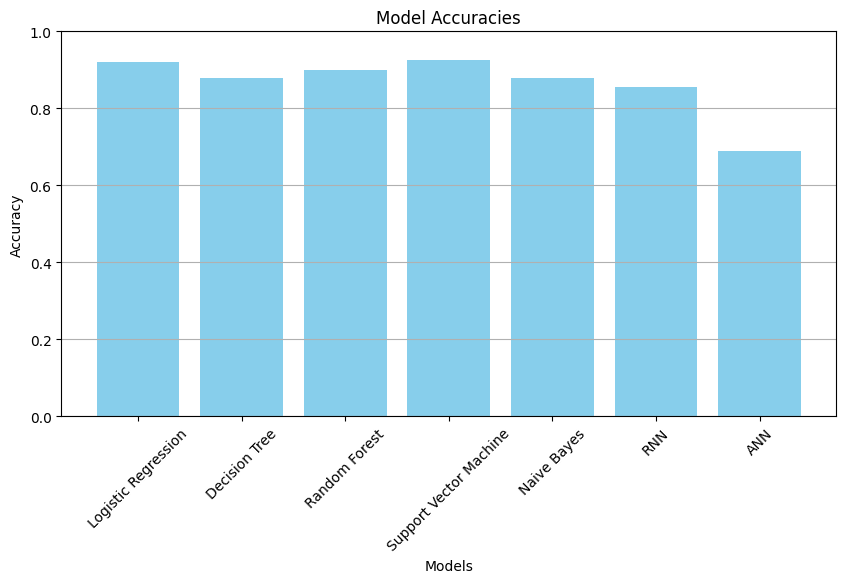

In [23]:
import pandas as pd
import re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt  # Import Matplotlib for plotting
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from keras.models import Sequential
from keras.layers import Dense, Embedding, SimpleRNN
from keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Load your DataFrame here
# recipe_df = pd.read_csv('your_data.csv')  # Uncomment and modify to load your dataset

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Store accuracies
accuracies = {}

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB()
}

# Train and evaluate traditional models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    accuracies[model_name] = accuracy  # Store accuracy
    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output

# Prepare data for RNN
max_words = 500
max_len = 100  # Adjust based on your dataset

# Tokenize the text data for RNN
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_rnn = pad_sequences(X_train_seq, maxlen=max_len)
X_test_rnn = pad_sequences(X_test_seq, maxlen=max_len)

# Build and train RNN model
rnn_model = Sequential()
rnn_model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
rnn_model.add(SimpleRNN(128, return_sequences=False))
rnn_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
rnn_model.fit(X_train_rnn, y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate RNN
rnn_y_pred = np.argmax(rnn_model.predict(X_test_rnn), axis=-1)
rnn_accuracy = accuracy_score(y_test, rnn_y_pred)
accuracies['RNN'] = rnn_accuracy  # Store RNN accuracy
print('RNN Accuracy:', rnn_accuracy)

# Build and train ANN model
ann_model = Sequential()
ann_model.add(Dense(128, activation='relu', input_shape=(X_train_tfidf.shape[1],)))
ann_model.add(Dense(64, activation='relu'))
ann_model.add(Dense(len(label_encoder.classes_), activation='softmax'))

ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train_tfidf.toarray(), y_train, epochs=5, batch_size=32, validation_split=0.1)

# Evaluate ANN
ann_y_pred = np.argmax(ann_model.predict(X_test_tfidf.toarray()), axis=-1)
ann_accuracy = accuracy_score(y_test, ann_y_pred)
accuracies['ANN'] = ann_accuracy  # Store ANN accuracy
print('ANN Accuracy:', ann_accuracy)

# Plotting the accuracies
plt.figure(figsize=(10, 5))
plt.bar(accuracies.keys(), accuracies.values(), color='skyblue')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Model Accuracies')
plt.ylim(0, 1)  # Set y-axis limits to 0-1 for accuracy
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
plt.grid(axis='y')  # Add gridlines for better visibility
plt.show()


In [15]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Example: Load the dataset (ensure you have 'Ingredients' and 'Recipe Name' columns)
# recipe_df = pd.read_csv('path_to_your_dataset.csv')

# Preprocess the ingredients
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  # Lowercase the text
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  # Remove special characters and numbers
    return ingredients

# Simplified features and target
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  # Features
y = recipe_df['Recipe Name']  # Target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

# Train and evaluate models
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  # Train
    y_pred = model.predict(X_test_tfidf)  # Predict
    accuracy = accuracy_score(y_test, y_pred)  # Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output
    print(classification_report(y_test, y_pred))  # Classification report


Logistic Regression Accuracy: 0.92
                    precision    recall  f1-score   support

          Beverage       0.00      0.00      0.00         1
           Dessert       0.00      0.00      0.00         5
Main Course - Rice       0.93      0.89      0.91        56
             Other       0.92      0.97      0.94       138

          accuracy                           0.92       200
         macro avg       0.46      0.47      0.46       200
      weighted avg       0.89      0.92      0.91       200

Decision Tree Accuracy: 0.86
                    precision    recall  f1-score   support

          Beverage       0.00      0.00      0.00         1
           Dessert       0.00      0.00      0.00         5
Main Course - Rice       0.87      0.93      0.90        56
             Other       0.92      0.88      0.90       138

          accuracy                           0.86       200
         macro avg       0.45      0.45      0.45       200
      weighted avg       0.88  

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

Random Forest Accuracy: 0.91
                    precision    recall  f1-score   support

          Beverage       0.00      0.00      0.00         1
           Dessert       0.00      0.00      0.00         5
Main Course - Rice       0.90      0.96      0.93        56
             Other       0.94      0.92      0.93       138

          accuracy                           0.91       200
         macro avg       0.46      0.47      0.47       200
      weighted avg       0.90      0.91      0.90       200

Support Vector Machine Accuracy: 0.93
                    precision    recall  f1-score   support

          Beverage       0.00      0.00      0.00         1
           Dessert       0.00      0.00      0.00         5
Main Course - Rice       0.95      0.93      0.94        56
             Other       0.93      0.96      0.95       138

          accuracy                           0.93       200
         macro avg       0.47      0.47      0.47       200
      weighted avg       0.9

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

Predictions: ['Chicken Curry']
Actual: ['Caesar Salad']
Accuracy: 0.00
